# HW1 — Introduction and Learnability: PAC vs. Agnostic PAC

**Statistical and Machine Learning** — M2 IM / IMDS / MIAGE, Université de Haute-Alsace

**Author:** Amina MENACER

---

**Goal.** Illustrate experimentally the difference between the PAC (realizable) and the Agnostic PAC learning frameworks, using an Empirical Risk Minimization (ERM) learner over the class of threshold classifiers on $\mathcal{X} = [0,1]$. We look at two different ways the realizability assumption can fail: **noisy labels** (Section 5) and **a target that is not in the class** (Section 6).

**Outline**
0. Setup and experimental parameters
1. Data generation
2. Implementation of ERM
3. Performance evaluation (empirical vs. true error)
4. Experimental verification of PAC learning (including a comparison with the finite-class bound of the course)
5. From PAC to Agnostic PAC: label noise
6. Agnostic PAC with a target outside the class
7. Conclusion

Only `numpy` and `matplotlib` are used; the learning algorithm is implemented from scratch.

## 0. Setup and experimental parameters

**Learning problem.** $\mathcal{X}=[0,1]$, $x \sim \mathcal{U}[0,1]$, target $f_\theta(x) = \mathbb{1}[x>\theta]$.
Hypothesis class $\mathcal{H} = \{h_t(x) = \mathbb{1}[x>t] : t \in [0,1]\}$.
The realizability assumption holds in Sections 1–4 since $f_\theta \in \mathcal{H}$.

**Parameter choices (and why).**

| Parameter | Value | Justification |
|---|---|---|
| $\theta$ | 0.3 | Away from the centre and from the borders; any $\theta \in (\varepsilon, 1)$ gives the same behaviour (checked in 4.4). |
| $\varepsilon$ | 0.05 | A 5% error tolerance: demanding enough that small samples fail, loose enough that the transition is visible within $m \le 200$. |
| $\delta$ | 0.05 | 95% confidence, a standard choice. |
| $\eta$ | 0.1 (main), sweep over $\{0.05, 0.1, 0.2, 0.3\}$ | Moderate noise for the main comparison; the sweep shows how noise changes the picture. |
| Interval target $(a, b)$ | $(0.3, 0.8)$ | Simple target that no threshold can represent (Section 6). |
| $m$ | $\{5,10,20,50,100,200\}$ (required) + a finer grid up to 500 | The required sizes for the tables; the finer grid contains them and gives smooth curves. |
| Repetitions $R$ | 1000 | Monte Carlo standard error of a probability $p$ is $\sqrt{p(1-p)/R} \le 0.016$. |
| Test set size | 100 000 | Standard error of the test error $\le \sqrt{0.25/10^5} \approx 0.0016$. |
| Random generators | one per experiment (`make_rng(tag)`) | Results do not depend on the order the cells are run in, and the tables and figures of a section use the same draws. |

In [1]:
import numpy as np
import matplotlib.pyplot as plt

SEED = 42

def make_rng(tag):
    # One independent random generator per experiment.
    # Each experiment gets its own stream, so results do not depend on the order cells are run in.
    return np.random.default_rng([SEED, tag])

THETA = 0.3          # target threshold
EPS = 0.05           # accuracy parameter epsilon
DELTA = 0.05         # confidence parameter delta
ETA = 0.1            # label-noise rate for the agnostic setting
ETAS = [0.05, 0.1, 0.2, 0.3]
M_GRID = [5, 10, 20, 50, 100, 200]                                                   # required sizes
M_FINE = np.unique(np.concatenate([np.round(np.geomspace(5, 500, 30)).astype(int), M_GRID]))  # smooth curves
R = 1000             # Monte Carlo repetitions
N_TEST = 100_000     # size of the independent test set

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

## 1. Data generation

Each example is drawn as $x \sim \mathcal{U}[0,1]$ and labelled $y = f_\theta(x)$.
In the agnostic setting each label is independently flipped with probability $\eta$:
$y = f_\theta(x) \oplus b$ with $b \sim \text{Bernoulli}(\eta)$.

The generator can draw a batch of $R$ independent samples at once (array of shape `(R, m)`), which makes the Monte Carlo experiments fast. The random generator is passed explicitly.

In [2]:
def generate_data(m, rng, theta=THETA, eta=0.0, n_rep=None):
    # Draw training samples. Returns X, y of shape (m,) or (n_rep, m).
    shape = (m,) if n_rep is None else (n_rep, m)
    X = rng.random(shape)
    y = (X > theta).astype(np.int8)
    if eta > 0:
        flip = rng.random(shape) < eta
        y = y ^ flip.astype(np.int8)
    return X, y

rng_clean, rng_noisy = make_rng(1), make_rng(2)
datasets = {m: generate_data(m, rng_clean) for m in M_GRID}                 # realizable
datasets_noisy = {m: generate_data(m, rng_noisy, eta=ETA) for m in M_GRID}  # agnostic
for m in M_GRID:
    X, y = datasets[m]
    _, yn = datasets_noisy[m]
    n_flipped = np.sum(yn != (datasets_noisy[m][0] > THETA))
    print(f"m={m:>3}: {y.sum():>3} positive / {m - y.sum():>3} negative (clean sample);"
          f"  {n_flipped:>2} flipped labels in the noisy sample")

m=  5:   4 positive /   1 negative (clean sample);   0 flipped labels in the noisy sample
m= 10:   9 positive /   1 negative (clean sample);   0 flipped labels in the noisy sample
m= 20:  16 positive /   4 negative (clean sample);   1 flipped labels in the noisy sample
m= 50:  32 positive /  18 negative (clean sample);   4 flipped labels in the noisy sample
m=100:  69 positive /  31 negative (clean sample);   7 flipped labels in the noisy sample
m=200: 143 positive /  57 negative (clean sample);  16 flipped labels in the noisy sample


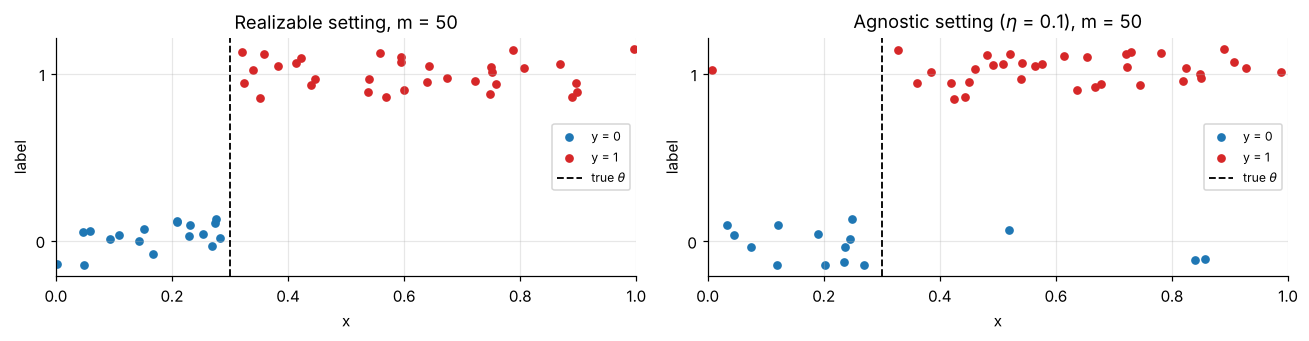

In [3]:
def plot_dataset(ax, X, y, title, theta=THETA, t_hat=None, theta_label=r"true $\theta$"):
    jitter = np.random.default_rng(0).uniform(-0.15, 0.15, size=len(X))
    ax.scatter(X[y == 0], y[y == 0] + jitter[y == 0], c="tab:blue", s=22, label="y = 0")
    ax.scatter(X[y == 1], y[y == 1] + jitter[y == 1], c="tab:red", s=22, label="y = 1")
    if theta is not None:
        ax.axvline(theta, color="k", ls="--", lw=1.2, label=theta_label)
    if t_hat is not None:
        ax.axvline(t_hat, color="tab:green", lw=1.5, label=r"ERM $\hat t$")
    ax.set_yticks([0, 1]); ax.set_xlim(0, 1); ax.set_xlabel("x"); ax.set_ylabel("label")
    ax.set_title(title); ax.legend(loc="center right", fontsize=8)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.2))
plot_dataset(axes[0], *datasets[50], "Realizable setting, m = 50")
plot_dataset(axes[1], *datasets_noisy[50], rf"Agnostic setting ($\eta$ = {ETA}), m = 50")
plt.tight_layout(); plt.show()

**Observation.** Left (clean labels): every point left of the dashed line is blue ($y=0$) and every point right of it is red ($y=1$). Right (noisy labels): a few points have the "wrong" colour on each side of $\theta$.

**Explanation.** Clean labels are produced by $f_\theta$, which is itself a threshold, so one threshold separates the sample perfectly. With noise, about $\eta m$ labels are flipped (4 out of 50 here). A flipped point sits in a region where every good threshold predicts the other label, so in general no threshold can fit all the points.

**Link to the course.** The left plot satisfies the realizability assumption: there is $h \in \mathcal H$ with $L_{\mathcal D}(h) = 0$. The right plot does not: this is the agnostic setting.

## 2. Implementation of ERM

**Reducing an infinite class to $m+1$ candidates.** For a fixed sample, $h_t$ and $h_{t'}$ make exactly the same predictions on the sample whenever no training point lies in $(\min(t,t'), \max(t,t')]$. Sorting the sample $x_{(1)} \le \dots \le x_{(m)}$, the empirical risk $L_S(h_t)$ is therefore piecewise constant in $t$, and it suffices to evaluate
$$t \in \{0, x_{(1)}, \dots, x_{(m)}\}.$$
Choosing $t = x_{(k)}$ means: the $k$ smallest points are predicted $0$, the others $1$.

**Computing all $m+1$ empirical risks in $O(m \log m)$.** With $C_k = \sum_{i \le k} y_{(i)}$ (number of 1-labels among the $k$ smallest points),
$$m \, L_S\big(h_{x_{(k)}}\big) = \underbrace{C_k}_{\text{1-labels predicted 0}} + \underbrace{(m-k) - (C_m - C_k)}_{\text{0-labels predicted 1}}.$$
A single sort and a cumulative sum give all candidates at once; the ERM returns the minimiser.

**Tie-breaking.** When several candidates reach the minimum, `argmin` keeps the smallest one. Within the selected interval $[x_{(k)}, x_{(k+1)})$, we take the left endpoint $t = x_{(k)}$. In the realizable case this gives a very simple rule: $\hat t$ is **the largest training point labelled 0** (or $0$ if there is none), and it is the unique minimiser among the candidates. This choice is analysed exactly in Section 4, and an alternative (midpoint) is compared in Section 4.5.

In [4]:
def erm_threshold(X, y):
    # ERM over threshold classifiers h_t(x) = 1[x > t].
    # Works on one sample (shape (m,)) or a batch (shape (R, m)).
    # Returns (t_hat, empirical_risk).
    X = np.atleast_2d(X); y = np.atleast_2d(y)
    n_rep, m = X.shape
    order = np.argsort(X, axis=1)
    Xs = np.take_along_axis(X, order, axis=1)
    ys = np.take_along_axis(y, order, axis=1).astype(np.int32)
    C = np.concatenate([np.zeros((n_rep, 1), np.int32), np.cumsum(ys, axis=1)], axis=1)  # C_0..C_m
    k = np.arange(m + 1)
    errors = C + (m - k) - (C[:, [m]] - C)            # m * L_S for each candidate, shape (n_rep, m+1)
    k_star = np.argmin(errors, axis=1)                # first minimiser
    candidates = np.concatenate([np.zeros((n_rep, 1)), Xs], axis=1)
    t_hat = candidates[np.arange(n_rep), k_star]
    emp_risk = errors[np.arange(n_rep), k_star] / m
    return t_hat.squeeze(), emp_risk.squeeze()

def empirical_risk(t, X, y):
    return np.mean((X > t).astype(np.int8) != y)

# Sanity check against brute force on a fine grid of thresholds
for (X, y) in [datasets[50], datasets_noisy[50], datasets_noisy[200]]:
    t_hat, ls = erm_threshold(X, y)
    grid = np.linspace(0, 1, 20001)
    brute = min(empirical_risk(t, X, y) for t in grid)
    assert abs(ls - brute) < 1e-12 and abs(ls - empirical_risk(t_hat, X, y)) < 1e-12
print("ERM matches brute-force minimisation on a 20 001-point grid.")

ERM matches brute-force minimisation on a 20 001-point grid.


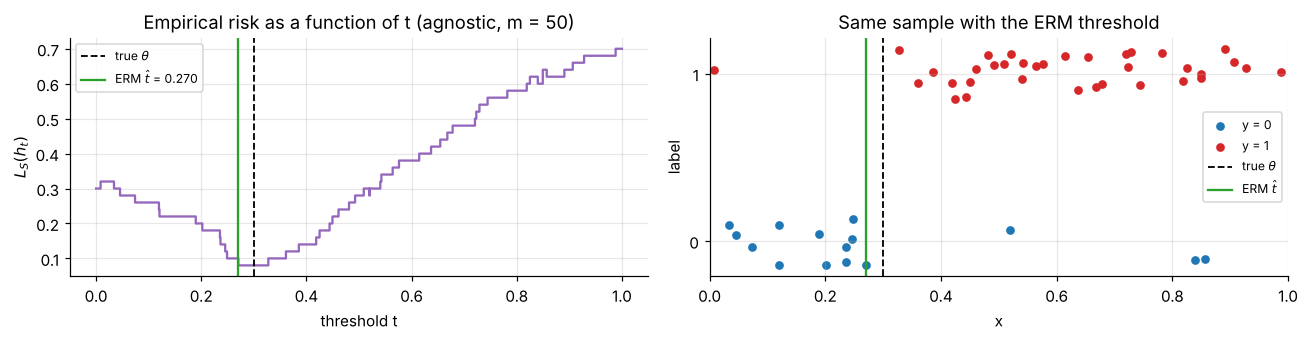

min_t L_S(h_t) = 0.080   (noise level eta = 0.1)


In [5]:
X, y = datasets_noisy[50]
t_hat, ls_hat = erm_threshold(X, y)
grid = np.linspace(0, 1, 2001)
risk_curve = [empirical_risk(t, X, y) for t in grid]

fig, axes = plt.subplots(1, 2, figsize=(12, 3.2))
axes[0].step(grid, risk_curve, where="post", color="tab:purple")
axes[0].axvline(THETA, color="k", ls="--", lw=1.2, label=r"true $\theta$")
axes[0].axvline(t_hat, color="tab:green", lw=1.5, label=rf"ERM $\hat t$ = {t_hat:.3f}")
axes[0].set_xlabel("threshold t"); axes[0].set_ylabel(r"$L_S(h_t)$")
axes[0].set_title(r"Empirical risk as a function of t (agnostic, m = 50)"); axes[0].legend(fontsize=8)
plot_dataset(axes[1], X, y, "Same sample with the ERM threshold", t_hat=t_hat)
plt.tight_layout(); plt.show()
print(f"min_t L_S(h_t) = {ls_hat:.3f}   (noise level eta = {ETA})")

**Observation.** $L_S(h_t)$ is a step function of $t$. Its minimum is $0.08$, not $0$, and $\hat t$ is close to $\theta$ but not equal to it.

**Explanation.** The predictions of $h_t$ only change when $t$ crosses a training point, so the curve is flat between two points. This is why the $m+1$ candidates are enough. Because some labels are flipped, no threshold fits everything, so the minimum is positive. It is even below $\eta = 0.1$: ERM picks the threshold that best fits *this* sample, including part of its noise.

**Link to the course.** ERM returns $h_S \in \arg\min_{h \in \mathcal H} L_S(h)$. The empirical risk is what the learner can see; the true risk $L_{\mathcal D}$ is what we actually care about.

## 3. Performance evaluation

**True error.** We estimate $L_{\mathcal D}(h_{\hat t})$ on an independent test set of $10^5$ points drawn from the same distribution.

**Closed-form check.** Because $x \sim \mathcal U[0,1]$, the true error is also available exactly:
- realizable: $h_t$ and $f_\theta$ disagree exactly on the interval between $t$ and $\theta$, so $L_{\mathcal D, f}(h_t) = |t-\theta|$;
- agnostic: on that interval the prediction is wrong unless the label was flipped, elsewhere it is wrong only if the label was flipped, so
$$L_{\mathcal D}(h_t) = (1-\eta)\,|t-\theta| + \eta\,(1-|t-\theta|) = \eta + (1-2\eta)\,|t-\theta|.$$

The table compares the test-set estimate with the exact value. Once they agree within Monte Carlo error, the experiments of Sections 4–6 use the exact formula, which removes test-set noise and is much faster.

In [6]:
def true_risk(t, theta=THETA, eta=0.0):
    return eta + (1 - 2 * eta) * np.abs(t - theta)

X_test, y_test = generate_data(N_TEST, make_rng(3))
X_test_n, y_test_n = generate_data(N_TEST, make_rng(4), eta=ETA)

def evaluation_table(data, X_te, y_te, eta, label):
    print(f"--- {label} ---")
    print(f"{'m':>4} | {'t_hat':>7} | {'L_S (train)':>11} | {'L_D (test set)':>14} | {'L_D (exact)':>11} | {'gap L_D - L_S':>13}")
    for m in M_GRID:
        X, y = data[m]
        t_hat, ls = erm_threshold(X, y)
        ld_test = empirical_risk(t_hat, X_te, y_te)
        ld_exact = true_risk(t_hat, eta=eta)
        print(f"{m:>4} | {t_hat:7.4f} | {ls:11.4f} | {ld_test:14.4f} | {ld_exact:11.4f} | {ld_exact - ls:13.4f}")

evaluation_table(datasets, X_test, y_test, 0.0, "Realizable")
evaluation_table(datasets_noisy, X_test_n, y_test_n, ETA, f"Agnostic (eta = {ETA})")

--- Realizable ---
   m |   t_hat | L_S (train) | L_D (test set) | L_D (exact) | gap L_D - L_S
   5 |  0.2460 |      0.0000 |         0.0533 |      0.0540 |        0.0540
  10 |  0.2065 |      0.0000 |         0.0935 |      0.0935 |        0.0935
  20 |  0.2453 |      0.0000 |         0.0541 |      0.0547 |        0.0547
  50 |  0.2829 |      0.0000 |         0.0166 |      0.0171 |        0.0171
 100 |  0.2887 |      0.0000 |         0.0110 |      0.0113 |        0.0113
 200 |  0.2989 |      0.0000 |         0.0011 |      0.0011 |        0.0011
--- Agnostic (eta = 0.1) ---
   m |   t_hat | L_S (train) | L_D (test set) | L_D (exact) | gap L_D - L_S
   5 |  0.2895 |      0.0000 |         0.1081 |      0.1084 |        0.1084
  10 |  0.2298 |      0.0000 |         0.1554 |      0.1562 |        0.1562
  20 |  0.1986 |      0.0500 |         0.1796 |      0.1811 |        0.1311
  50 |  0.2701 |      0.0800 |         0.1231 |      0.1240 |        0.0440
 100 |  0.2925 |      0.0700 |         0

**Observation.**
- The "test set" and "exact" columns agree to about $10^{-3}$.
- Realizable: $L_S = 0$ for every $m$, but the true error is not small for small samples ($0.09$ at $m=10$); it drops to $0.001$ at $m=200$.
- Agnostic: $L_S = 0$ for $m=5$ and $m=10$, then it becomes positive and stays below $\eta$, while $L_{\mathcal D}$ always stays above $\eta = 0.1$.

**Explanation.**
- The standard error of the test estimate is about $0.0016$, so this agreement validates both the code and the closed-form formula.
- Realizable: the sample is always separable, so ERM always reaches zero training error, whatever the quality of $\hat t$. With few points, the gap between the largest 0-labelled point and $\theta$ can be wide.
- Agnostic: the samples of size 5 and 10 happen to contain no flipped label (see the output of Section 1), so they look realizable. For larger samples ERM fits part of the noise, so $L_S$ is optimistic, while $L_{\mathcal D} \ge \eta$ for every threshold by the formula.

**Link to the course.** A small training error does not prove a small true error. This is why the course measures success with $L_{\mathcal D}$ and asks for a guarantee that holds *with probability at least $1-\delta$ over the sample*.

These are single draws and therefore noisy; the next sections repeat each experiment $R=1000$ times.

## 4. Experimental verification of PAC learning

### 4.1 What theory predicts for this ERM

In the realizable case $\hat t$ is the largest training point in $[0,\theta]$ (or $0$), so $L_{\mathcal D,f}(h_{\hat t}) = \theta - \hat t$. For $\varepsilon < \theta$:
$$L_{\mathcal D,f}(h_{\hat t}) > \varepsilon \iff \text{no training point falls in } (\theta-\varepsilon, \theta] \quad\Longrightarrow\quad \Pr\big[L_{\mathcal D,f}(h_{\hat t}) > \varepsilon\big] = (1-\varepsilon)^m \le e^{-\varepsilon m}.$$

This gives the **exact** minimal sample size for this algorithm: $m^\star(\varepsilon,\delta) = \left\lceil \dfrac{\ln \delta}{\ln(1-\varepsilon)} \right\rceil$.

Using $1-\varepsilon \le e^{-\varepsilon}$, a simpler sufficient size is $m \ge \ln(1/\delta)/\varepsilon$. Be careful: this is **not** an independent bound from the course. It is derived from the exact formula above, so it is naturally very close to $m^\star$. The real comparison with the course bound for finite classes is done in Section 4.3.

Note: this exact formula holds for *our* ERM (left endpoint). A different ERM, e.g. the midpoint between the two classes, has a different (smaller) failure probability; see 4.5.

### 4.2 Monte Carlo estimate of $\Pr[L_{\mathcal D,f}(h_S) > \varepsilon]$

In [7]:
def run_mc(m, rng, eta=0.0, n_rep=R, theta=THETA):
    # R independent training sets of size m -> arrays of t_hat, L_S, L_D.
    X, y = generate_data(m, rng, theta=theta, eta=eta, n_rep=n_rep)
    t_hat, ls = erm_threshold(X, y)
    return t_hat, ls, true_risk(t_hat, theta=theta, eta=eta)

def wilson_ci(p_hat, n, z=1.96):
    # 95% Wilson interval for a binomial proportion.
    denom = 1 + z**2 / n
    centre = (p_hat + z**2 / (2 * n)) / denom
    half = z * np.sqrt(p_hat * (1 - p_hat) / n + z**2 / (4 * n**2)) / denom
    return centre - half, centre + half

# One Monte Carlo run per m. The table and the figures below all use these same draws.
rng_real = make_rng(10)
real = {m: run_mc(m, rng_real) for m in M_FINE}
p_fail = np.array([np.mean(real[m][2] > EPS) for m in M_FINE])
lo, hi = wilson_ci(p_fail, R)

m_exact = int(np.ceil(np.log(DELTA) / np.log(1 - EPS)))
m_bound = int(np.ceil(np.log(1 / DELTA) / EPS))
m_mc = next((int(m) for m, p in zip(M_FINE, p_fail) if p <= DELTA), None)

print(f"{'m':>4} | {'P_hat[L_D > eps]':>16} | {'95% CI':>15} | {'exact (1-eps)^m':>15} | {'bound e^(-eps m)':>16}")
for m in M_GRID:
    i = list(M_FINE).index(m)
    print(f"{m:>4} | {p_fail[i]:16.3f} | [{lo[i]:.3f}, {hi[i]:.3f}] | {(1-EPS)**m:15.3f} | {np.exp(-EPS*m):16.3f}")
print(f"\nSample complexity for eps={EPS}, delta={DELTA}:")
print(f"  exact m* = ceil(ln(delta)/ln(1-eps)) = {m_exact}")
print(f"  from the inequality 1-eps <= e^(-eps): ln(1/delta)/eps = {m_bound}")
print(f"  smallest m on the Monte Carlo grid with P_hat <= delta: {m_mc}"
      f"  (grid points around it: {[int(v) for v in M_FINE if 40 <= v <= 80]})")

   m | P_hat[L_D > eps] |          95% CI | exact (1-eps)^m | bound e^(-eps m)
   5 |            0.771 | [0.744, 0.796] |           0.774 |            0.779
  10 |            0.604 | [0.573, 0.634] |           0.599 |            0.607
  20 |            0.361 | [0.332, 0.391] |           0.358 |            0.368
  50 |            0.077 | [0.062, 0.095] |           0.077 |            0.082
 100 |            0.005 | [0.002, 0.012] |           0.006 |            0.007
 200 |            0.000 | [0.000, 0.004] |           0.000 |            0.000

Sample complexity for eps=0.05, delta=0.05:
  exact m* = ceil(ln(delta)/ln(1-eps)) = 59
  from the inequality 1-eps <= e^(-eps): ln(1/delta)/eps = 60
  smallest m on the Monte Carlo grid with P_hat <= delta: 63  (grid points around it: [46, 50, 54, 63, 74])


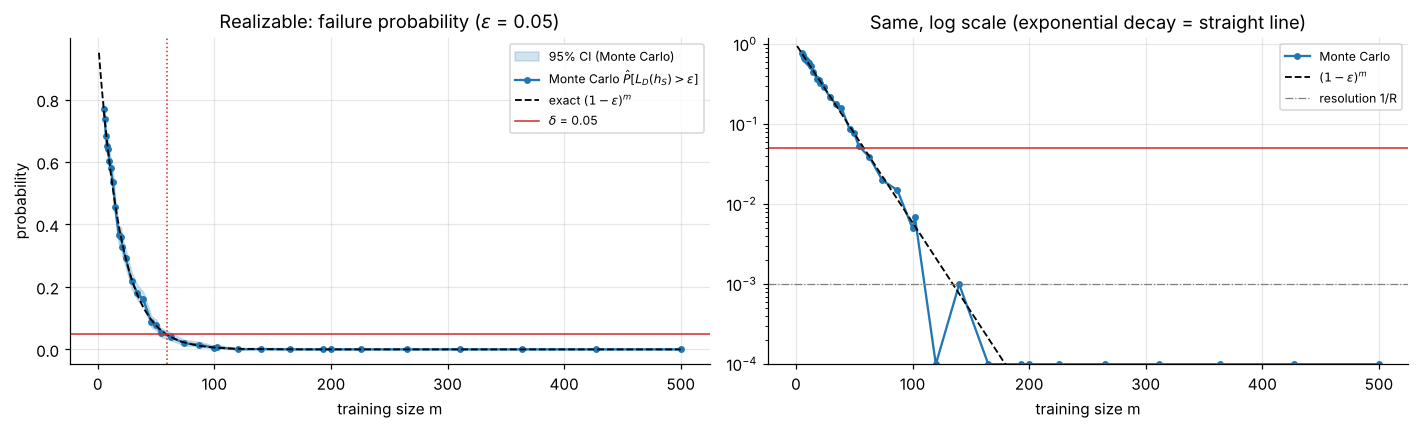

In [8]:
mm = np.arange(1, 501)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
ax = axes[0]
ax.fill_between(M_FINE, lo, hi, color="tab:blue", alpha=0.2, label="95% CI (Monte Carlo)")
ax.plot(M_FINE, p_fail, "o-", ms=3.5, color="tab:blue", label=r"Monte Carlo $\hat P[L_{D}(h_S)>\varepsilon]$")
ax.plot(mm, (1 - EPS) ** mm, "k--", lw=1.2, label=r"exact $(1-\varepsilon)^m$")
ax.axhline(DELTA, color="tab:red", lw=1, label=rf"$\delta$ = {DELTA}")
ax.axvline(m_exact, color="tab:red", ls=":", lw=1)
ax.set_xlabel("training size m"); ax.set_ylabel("probability")
ax.set_title(rf"Realizable: failure probability ($\varepsilon$ = {EPS})")
ax.legend(fontsize=8)

ax = axes[1]
ax.semilogy(M_FINE, np.maximum(p_fail, 1 / (10 * R)), "o-", ms=3.5, color="tab:blue", label="Monte Carlo")
ax.semilogy(mm, (1 - EPS) ** mm, "k--", lw=1.2, label=r"$(1-\varepsilon)^m$")
ax.axhline(DELTA, color="tab:red", lw=1); ax.axhline(1 / R, color="grey", lw=0.8, ls="-.", label="resolution 1/R")
ax.set_ylim(1e-4, 1.2); ax.set_xlabel("training size m"); ax.set_title("Same, log scale (exponential decay = straight line)")
ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

**Observation.** The Monte Carlo estimates follow the exact curve $(1-\varepsilon)^m$, and every confidence interval in the table contains the exact value. On the log scale the curve is a straight line. The failure probability goes below $\delta$ between $m=54$ and $m=63$ on our grid, consistent with the exact value $m^\star = 59$.

**Explanation.** The learner fails only if no training point falls in $(\theta-\varepsilon, \theta]$, an interval of probability $\varepsilon$. For $m$ independent points this happens with probability $(1-\varepsilon)^m = e^{m\ln(1-\varepsilon)}$, which decreases exponentially with $m$. On the log plot, points equal to 0 are drawn at $1/(10R)$: below $1/R = 10^{-3}$, 1000 repetitions cannot measure the probability any more.

**Link to the course.** This is the PAC guarantee: for $m \ge m^\star(\varepsilon,\delta)$, $\Pr[L_{\mathcal D,f}(h_S) \le \varepsilon] \ge 1-\delta$. The class of thresholds is infinite and still PAC learnable, so a finite class is sufficient for learnability but not necessary.

### 4.3 Comparison with the course bound for finite classes

For a **finite** class under realizability, the course shows that every ERM is a PAC learner as soon as
$$m \ge \frac{\log(|\mathcal H|/\delta)}{\varepsilon}.$$
This bound cannot be used for all thresholds, since $|\mathcal H| = \infty$. To use it, we restrict ERM to a finite grid of thresholds $\mathcal H_N = \{h_t : t \in \{0, \tfrac1N, \dots, 1\}\}$, so $|\mathcal H_N| = N+1$. Since $\theta = 0.3$ is on the grid when $N$ is a multiple of 10, realizability still holds.

For each $N$ we compare three numbers:
- the **course bound** $\lceil \log(|\mathcal H_N|/\delta)/\varepsilon \rceil$;
- the **exact** sample size of ERM on the grid (same reasoning as in 4.1: ERM picks the smallest grid point above the largest 0-labelled point);
- a **Monte Carlo** estimate ($m$ on a grid of step 5, $R = 1000$).

In [9]:
def erm_grid(X, y, grid):
    # ERM over the finite class H_N = {h_t : t in grid}. Returns the first minimiser (smallest t).
    X = np.atleast_2d(X); y = np.atleast_2d(y)
    n_rep, m = X.shape
    order = np.argsort(X, axis=1)
    Xs = np.take_along_axis(X, order, axis=1)
    ys = np.take_along_axis(y, order, axis=1).astype(np.int32)
    C = np.concatenate([np.zeros((n_rep, 1), np.int32), np.cumsum(ys, axis=1)], axis=1)
    t_hat = np.empty(n_rep)
    for r in range(n_rep):
        k = np.searchsorted(Xs[r], grid, side="right")          # number of points <= t
        err = C[r, k] + (m - k) - (C[r, m] - C[r, k])
        t_hat[r] = grid[np.argmin(err)]
    return t_hat

def exact_fail_grid(m, N, eps=EPS, theta=THETA):
    # ERM on the grid picks the smallest grid point >= largest 0-labelled point.
    # It fails iff that point is below theta - eps, i.e. iff no sample falls in (g, theta],
    # where g is the largest grid point strictly below theta - eps.
    g = np.floor((theta - eps) * N - 1e-9) / N
    return (1 - (theta - g)) ** m

N_LIST = [100, 1_000, 10_000]
M_FIN = np.arange(10, 101, 5)
rng_fin = make_rng(15)
fin = {}
for N in N_LIST:
    grid_N = np.arange(N + 1) / N
    fin[N] = np.array([np.mean(true_risk(erm_grid(*generate_data(m, rng_fin, n_rep=R), grid_N)) > EPS)
                       for m in M_FIN])

def m_finite_bound(size):
    return int(np.ceil(np.log(size / DELTA) / EPS))

print(f"{'class':>16} | {'|H|':>10} | {'course bound log(|H|/delta)/eps':>31} | {'exact m* of ERM':>15} | {'Monte Carlo m (step 5)':>22}")
for N in N_LIST:
    m_ex = next(m for m in range(1, 1000) if exact_fail_grid(m, N) <= DELTA)
    m_mc_N = next((int(m) for m, p in zip(M_FIN, fin[N]) if p <= DELTA), None)
    print(f"{'grid, N=' + str(N):>16} | {N + 1:>10} | {m_finite_bound(N + 1):>31} | {m_ex:>15} | {m_mc_N:>22}")
for N in [10**6, 10**9]:
    print(f"{'grid, N=1e' + str(int(np.log10(N))):>16} | {N + 1:>10.0e} | {m_finite_bound(N + 1):>31} | {'~' + str(m_exact):>15} | {'-':>22}")
print(f"{'all thresholds':>16} | {'infinite':>10} | {'(does not apply)':>31} | {m_exact:>15} | {m_mc:>22}")

           class |        |H| | course bound log(|H|/delta)/eps | exact m* of ERM | Monte Carlo m (step 5)
     grid, N=100 |        101 |                             153 |              49 |                     50
    grid, N=1000 |       1001 |                             199 |              58 |                     55
   grid, N=10000 |      10001 |                             245 |              59 |                     60
     grid, N=1e6 |      1e+06 |                             337 |             ~59 |                      -
     grid, N=1e9 |      1e+09 |                             475 |             ~59 |                      -
  all thresholds |   infinite |                (does not apply) |              59 |                     63


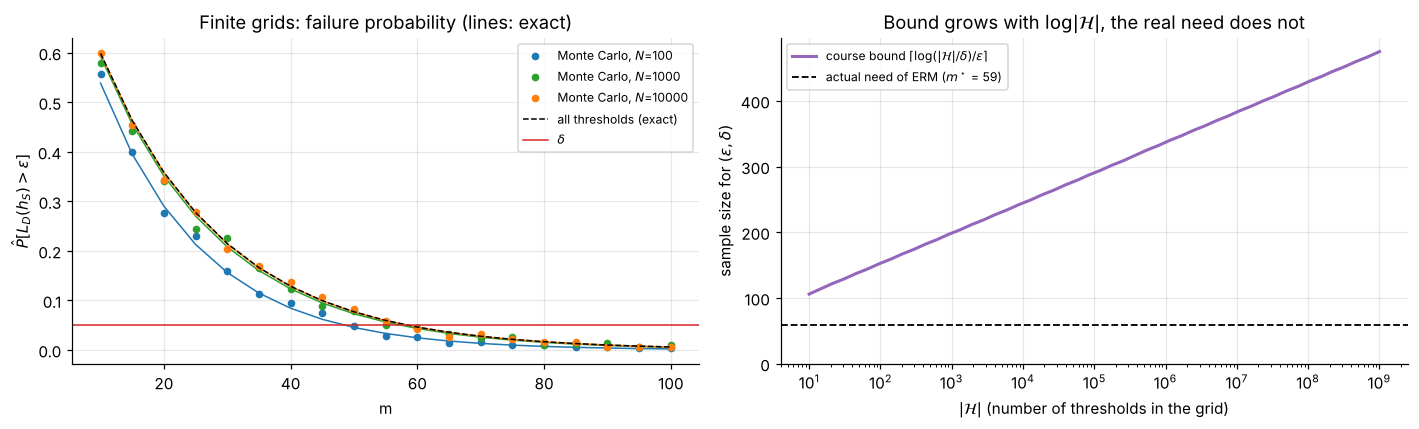

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
ax = axes[0]
for N, c in zip(N_LIST, ["tab:blue", "tab:green", "tab:orange"]):
    ax.plot(M_FIN, fin[N], "o", ms=4, color=c, label=rf"Monte Carlo, $N$={N}")
    ax.plot(M_FIN, [exact_fail_grid(m, N) for m in M_FIN], "-", lw=1, color=c)
ax.plot(M_FIN, (1 - EPS) ** M_FIN, "k--", lw=1, label="all thresholds (exact)")
ax.axhline(DELTA, color="tab:red", lw=1, label=r"$\delta$")
ax.set_xlabel("m"); ax.set_ylabel(r"$\hat P[L_D(h_S) > \varepsilon]$")
ax.set_title("Finite grids: failure probability (lines: exact)"); ax.legend(fontsize=8)

ax = axes[1]
sizes = np.logspace(1, 9, 50)
ax.semilogx(sizes, [m_finite_bound(s) for s in sizes], color="tab:purple", lw=2,
            label=r"course bound $\lceil \log(|\mathcal{H}|/\delta)/\varepsilon \rceil$")
ax.axhline(m_exact, color="k", ls="--", lw=1.2, label=rf"actual need of ERM ($m^\star$ = {m_exact})")
ax.set_xlabel(r"$|\mathcal{H}|$ (number of thresholds in the grid)"); ax.set_ylabel(r"sample size for $(\varepsilon,\delta)$")
ax.set_ylim(0, None); ax.set_title(r"Bound grows with $\log|\mathcal{H}|$, the real need does not"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

**Observation.** The course bound gives 153, 199 and 245 examples for $N = 100, 1000, 10\,000$, and it keeps growing (475 for $N = 10^9$). The real need of ERM stays between 49 and 59 for every $N$. The Monte Carlo values agree with the exact ones up to the step of the grid (5) and Monte Carlo noise. The bound is about 3 to 8 times too pessimistic.

**Explanation.** The bound comes from a union bound over all the hypotheses: it pays $\log|\mathcal H|$ to control every "bad" hypothesis at the same time. But thresholds are strongly correlated: two close thresholds make almost the same predictions, so the bound counts many hypotheses that are almost identical. The real need does not depend on $N$. A coarse grid even helps a little, because ERM rounds $\hat t$ up to the next grid point, closer to $\theta$; this is why $N = 100$ needs only 49 examples.

**Link to the course.** The finite-class bound is a sufficient condition, not an exact value. It explodes as $N \to \infty$, while the infinite class is still learnable with about 59 examples. Counting hypotheses is therefore the wrong measure of complexity for this class; this is the motivation for a measure that does not depend on $|\mathcal H|$ (the VC dimension, later in the course).

### 4.4 Influence of $\varepsilon$, $\delta$ and $\theta$

PAC learnability asks for a guarantee for **every** $\varepsilon, \delta$ and **every** target in the class. We therefore vary the parameters instead of fixing them:
- the required sample size should scale like $1/\varepsilon$;
- it should grow only like $\log(1/\delta)$;
- for $\varepsilon < \theta$ it should not depend on $\theta$.

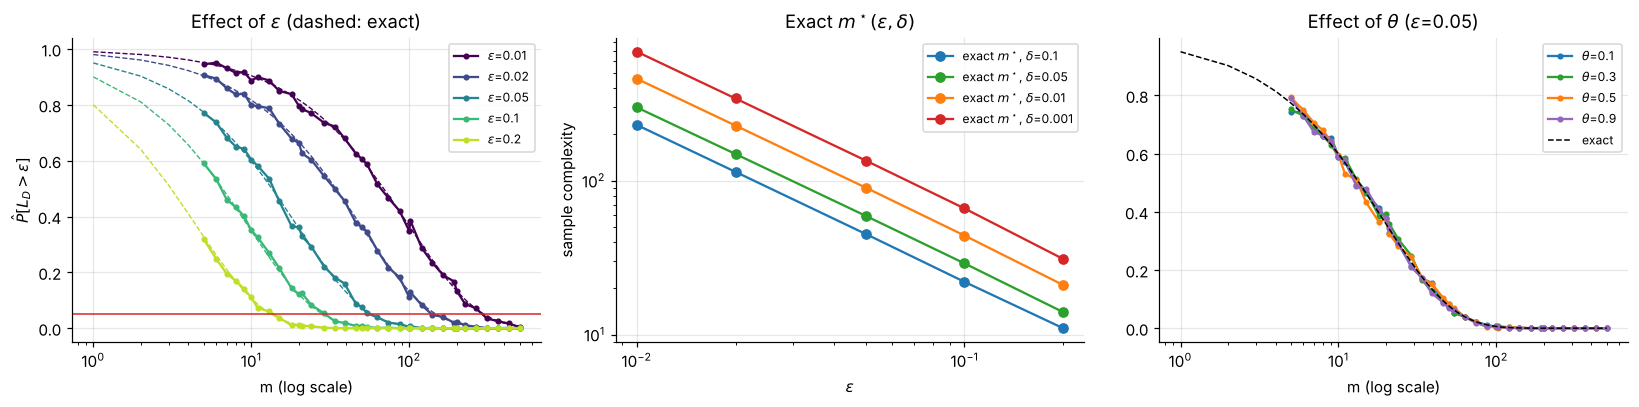

Exact sample complexity m*(eps, delta):
  delta=0.1    eps=0.01:  230  eps=0.02:  114  eps=0.05:   45  eps=0.1:   22  eps=0.2:   11
  delta=0.05   eps=0.01:  299  eps=0.02:  149  eps=0.05:   59  eps=0.1:   29  eps=0.2:   14
  delta=0.01   eps=0.01:  459  eps=0.02:  228  eps=0.05:   90  eps=0.1:   44  eps=0.2:   21
  delta=0.001  eps=0.01:  688  eps=0.02:  342  eps=0.05:  135  eps=0.1:   66  eps=0.2:   31


In [11]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))

ax = axes[0]
for eps, c in zip([0.01, 0.02, 0.05, 0.1, 0.2], plt.cm.viridis(np.linspace(0, 0.9, 5))):
    ax.plot(M_FINE, [np.mean(real[m][2] > eps) for m in M_FINE], "o-", ms=3, color=c, label=rf"$\varepsilon$={eps}")
    ax.plot(mm, (1 - eps) ** mm, "--", color=c, lw=0.9)
ax.axhline(DELTA, color="tab:red", lw=1); ax.set_xscale("log")
ax.set_xlabel("m (log scale)"); ax.set_ylabel(r"$\hat P[L_D > \varepsilon]$")
ax.set_title(r"Effect of $\varepsilon$ (dashed: exact)"); ax.legend(fontsize=8)

ax = axes[1]
eps_vals = np.array([0.01, 0.02, 0.05, 0.1, 0.2])
for d, c in zip([0.1, 0.05, 0.01, 0.001], ["tab:blue", "tab:green", "tab:orange", "tab:red"]):
    ax.loglog(eps_vals, np.ceil(np.log(d) / np.log(1 - eps_vals)), "o-", color=c, label=rf"exact $m^\star$, $\delta$={d}")
ax.set_xlabel(r"$\varepsilon$"); ax.set_ylabel("sample complexity")
ax.set_title(r"Exact $m^\star(\varepsilon, \delta)$"); ax.legend(fontsize=8)

ax = axes[2]
for i, (th, c) in enumerate(zip([0.1, 0.3, 0.5, 0.9], ["tab:blue", "tab:green", "tab:orange", "tab:purple"])):
    rng_th = make_rng(20 + i)
    ax.plot(M_FINE, [np.mean(run_mc(m, rng_th, theta=th)[2] > EPS) for m in M_FINE], "o-", ms=3, color=c, label=rf"$\theta$={th}")
ax.plot(mm, (1 - EPS) ** mm, "k--", lw=1, label="exact")
ax.set_xscale("log"); ax.set_xlabel("m (log scale)")
ax.set_title(rf"Effect of $\theta$ ($\varepsilon$={EPS})"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

print("Exact sample complexity m*(eps, delta):")
for d in [0.1, 0.05, 0.01, 0.001]:
    print(f"  delta={d:<6}", "  ".join(f"eps={e}: {int(np.ceil(np.log(d)/np.log(1-e))):>4}" for e in eps_vals))

**Observation.** Dividing $\varepsilon$ by 10 multiplies $m^\star$ by about 10 (slope $-1$ on the log-log plot). Going from $\delta = 0.1$ to $\delta = 0.001$ (100 times more confidence) multiplies $m^\star$ by only 3 (45 → 135 for $\varepsilon = 0.05$). The curves for $\theta = 0.1, 0.3, 0.5, 0.9$ overlap.

**Explanation.** $m^\star = \ln(1/\delta) / (-\ln(1-\varepsilon)) \approx \ln(1/\delta)/\varepsilon$: linear in $1/\varepsilon$, logarithmic in $1/\delta$. The value of $\theta$ does not matter because failure only depends on the interval $(\theta-\varepsilon, \theta]$, which has probability $\varepsilon$ wherever it is (as long as $\varepsilon < \theta$).

**Link to the course.** In the definition of PAC learnability, one function $m_{\mathcal H}(\varepsilon, \delta)$ must work for every target. The experiment shows that the same $m^\star$ works for every $\theta$. It also shows the usual message: accuracy is expensive, confidence is cheap.

### 4.5 Empirical vs. true error across repetitions, and the choice of ERM

In the realizable setting $L_S(h_S) = 0$ for every sample, while $\mathbb E[L_{\mathcal D,f}(h_S)] = \mathbb E[\theta - \hat t] = \int_0^\theta (1-s)^m\,ds = \dfrac{1-(1-\theta)^{m+1}}{m+1} \approx \dfrac{1}{m+1}$.

ERM is not unique here: any $t \in [\hat t, \hat t_{\text{right}})$, where $\hat t_{\text{right}}$ is the smallest point labelled 1, also has zero empirical error. We compare our left-endpoint rule with the **midpoint** rule $t = (\hat t + \hat t_{\text{right}})/2$. Both are valid ERM algorithms. To make the comparison fair, both rules are applied to the **same** training samples.

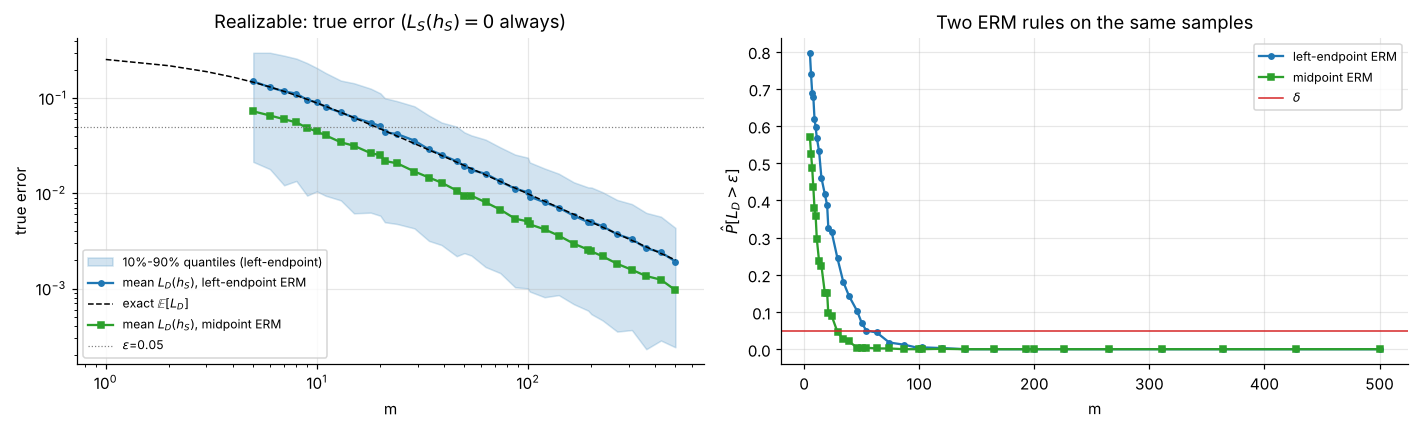

log-log slope of E[L_D] vs m (left-endpoint ERM): -0.96  (theory: -1)
m = 200: mean error left = 0.0050, midpoint = 0.0025, ratio = 0.49
m = 200: midpoint is at least as good as left-endpoint on 75% of the samples


In [12]:
def erm_midpoint_realizable(X, y):
    left = np.where(y == 0, X, 0.0).max(axis=1)
    right = np.where(y == 1, X, 1.0).min(axis=1)
    return (left + right) / 2

# Paired comparison: both rules are applied to the SAME training samples.
rng_pair = make_rng(30)
mean_ld, q10, q90, mean_ld_mid, p_left, p_mid = [], [], [], [], [], []
for m in M_FINE:
    X, y = generate_data(m, rng_pair, n_rep=R)
    t_left, _ = erm_threshold(X, y)
    t_mid = erm_midpoint_realizable(X, y)
    ld, ld_mid = true_risk(t_left), true_risk(t_mid)
    mean_ld.append(ld.mean()); q10.append(np.quantile(ld, 0.1)); q90.append(np.quantile(ld, 0.9))
    mean_ld_mid.append(ld_mid.mean()); p_left.append(np.mean(ld > EPS)); p_mid.append(np.mean(ld_mid > EPS))
    if m == 200:
        frac_better = np.mean(ld_mid <= ld)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
ax = axes[0]
ax.fill_between(M_FINE, q10, q90, alpha=0.2, color="tab:blue", label="10%-90% quantiles (left-endpoint)")
ax.loglog(M_FINE, mean_ld, "o-", ms=3.5, color="tab:blue", label=r"mean $L_D(h_S)$, left-endpoint ERM")
ax.loglog(mm, (1 - (1 - THETA) ** (mm + 1)) / (mm + 1), "k--", lw=1, label=r"exact $\mathbb{E}[L_D]$")
ax.loglog(M_FINE, mean_ld_mid, "s-", ms=3.5, color="tab:green", label=r"mean $L_D(h_S)$, midpoint ERM")
ax.axhline(EPS, color="grey", lw=0.8, ls=":", label=rf"$\varepsilon$={EPS}")
ax.set_xlabel("m"); ax.set_ylabel("true error"); ax.set_title(r"Realizable: true error ($L_S(h_S)=0$ always)")
ax.legend(fontsize=8)
ax = axes[1]
ax.plot(M_FINE, p_left, "o-", ms=3.5, label="left-endpoint ERM")
ax.plot(M_FINE, p_mid, "s-", ms=3.5, color="tab:green", label="midpoint ERM")
ax.axhline(DELTA, color="tab:red", lw=1, label=r"$\delta$")
ax.set_xlabel("m"); ax.set_ylabel(r"$\hat P[L_D > \varepsilon]$"); ax.set_title("Two ERM rules on the same samples")
ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

i200 = list(M_FINE).index(200)
slope = np.polyfit(np.log(M_FINE), np.log(mean_ld), 1)[0]
print(f"log-log slope of E[L_D] vs m (left-endpoint ERM): {slope:.2f}  (theory: -1)")
print(f"m = 200: mean error left = {mean_ld[i200]:.4f}, midpoint = {mean_ld_mid[i200]:.4f}, ratio = {mean_ld_mid[i200] / mean_ld[i200]:.2f}")
print(f"m = 200: midpoint is at least as good as left-endpoint on {100 * frac_better:.0f}% of the samples")

**Observation.** The mean true error decreases like $1/m$ (fitted slope $-0.96$) and follows the exact formula. The midpoint rule halves the mean error (0.0025 against 0.0050 at $m = 200$) and is at least as good as the left-endpoint rule on 75% of the samples. Yet both rules have zero training error on every sample.

**Explanation.** The left-endpoint rule always stays on the left of $\theta$: its error is the full gap between the largest 0-labelled point and $\theta$, about $1/(m+1)$ on average. The midpoint rule sits in the middle of the uncertainty interval $[\hat t, \hat t_{\text{right}})$, so on average it is closer to $\theta$.

**Link to the course.** Every ERM is a PAC learner here, but PAC theory controls how the error decreases with $m$, not the constant in front. The training error cannot tell the two rules apart: choosing between them is an inductive bias.

## 5. From PAC to Agnostic PAC: label noise

We now flip each label with probability $\eta$. The realizability assumption fails: no $h \in \mathcal H$ has zero true error. From Section 3,
$$L_{\mathcal D}(h_t) = \eta + (1-2\eta)|t-\theta|, \qquad \min_{h\in\mathcal H} L_{\mathcal D}(h) = L_{\mathcal D}(h_\theta) = \eta.$$
Since $\eta < 1/2$, $P(y=1 \mid x) > 1/2 \iff x > \theta$, so $h_\theta$ is also the Bayes optimal predictor: the class still contains the best possible classifier, and the error $\eta$ comes from the noise only. (Section 6 looks at the harder case where it does not.)

The relevant criterion is the **agnostic** one: $L_{\mathcal D}(h_S) \le \min_{h} L_{\mathcal D}(h) + \varepsilon = \eta + \varepsilon$.

The naive PAC event $\{L_{\mathcal D}(h_S) > \varepsilon\}$ does not need a simulation: $L_{\mathcal D}(h) \ge \eta$ for every $h$, so when $\varepsilon < \eta$ this event is **certain**, for every sample and every $m$.

In [13]:
# One Monte Carlo run per m; the table and the figure below use the same draws.
rng_agn = make_rng(40)
agn = {m: run_mc(m, rng_agn, eta=ETA) for m in M_FINE}

def summarise(res):
    ls = np.array([res[m][1].mean() for m in M_FINE])
    ld = np.array([res[m][2].mean() for m in M_FINE])
    p_ls0 = np.array([np.mean(res[m][1] == 0) for m in M_FINE])
    return ls, ld, p_ls0

ls_r, ld_r, p0_r = summarise(real)
ls_a, ld_a, p0_a = summarise(agn)
p_agn = np.array([np.mean(agn[m][2] > ETA + EPS) for m in M_FINE])
lo0, hi0 = wilson_ci(p0_a, R)

print(f"Agnostic setting, eta = {ETA}.  Note: L_D(h) >= eta = {ETA} > eps = {EPS} for EVERY h,")
print(f"so P[L_D(h_S) > eps] = 1 for every m. This is certain, so it is not simulated.\n")
print(f"{'m':>4} | {'mean L_S':>8} | {'mean L_D':>8} | {'P[L_S=0]':>8} | {'95% CI':>15} | {'lower bnd (1-eta)^m':>19} | {'P[L_D>eta+eps]':>14}")
for m in M_GRID:
    i = list(M_FINE).index(m)
    print(f"{m:>4} | {ls_a[i]:8.4f} | {ld_a[i]:8.4f} | {p0_a[i]:8.3f} | [{lo0[i]:.3f}, {hi0[i]:.3f}] | {(1-ETA)**m:19.4f} | {p_agn[i]:14.3f}")

Agnostic setting, eta = 0.1.  Note: L_D(h) >= eta = 0.1 > eps = 0.05 for EVERY h,
so P[L_D(h_S) > eps] = 1 for every m. This is certain, so it is not simulated.

   m | mean L_S | mean L_D | P[L_S=0] |          95% CI | lower bnd (1-eta)^m | P[L_D>eta+eps]
   5 |   0.0612 |   0.2337 |    0.722 | [0.693, 0.749] |              0.5905 |          0.774
  10 |   0.0770 |   0.1908 |    0.449 | [0.418, 0.480] |              0.3487 |          0.623
  20 |   0.0870 |   0.1535 |    0.162 | [0.140, 0.186] |              0.1216 |          0.391
  50 |   0.0945 |   0.1215 |    0.005 | [0.002, 0.012] |              0.0052 |          0.103
 100 |   0.0988 |   0.1113 |    0.000 | [0.000, 0.004] |              0.0000 |          0.018
 200 |   0.0991 |   0.1055 |    0.000 | [0.000, 0.004] |              0.0000 |          0.001


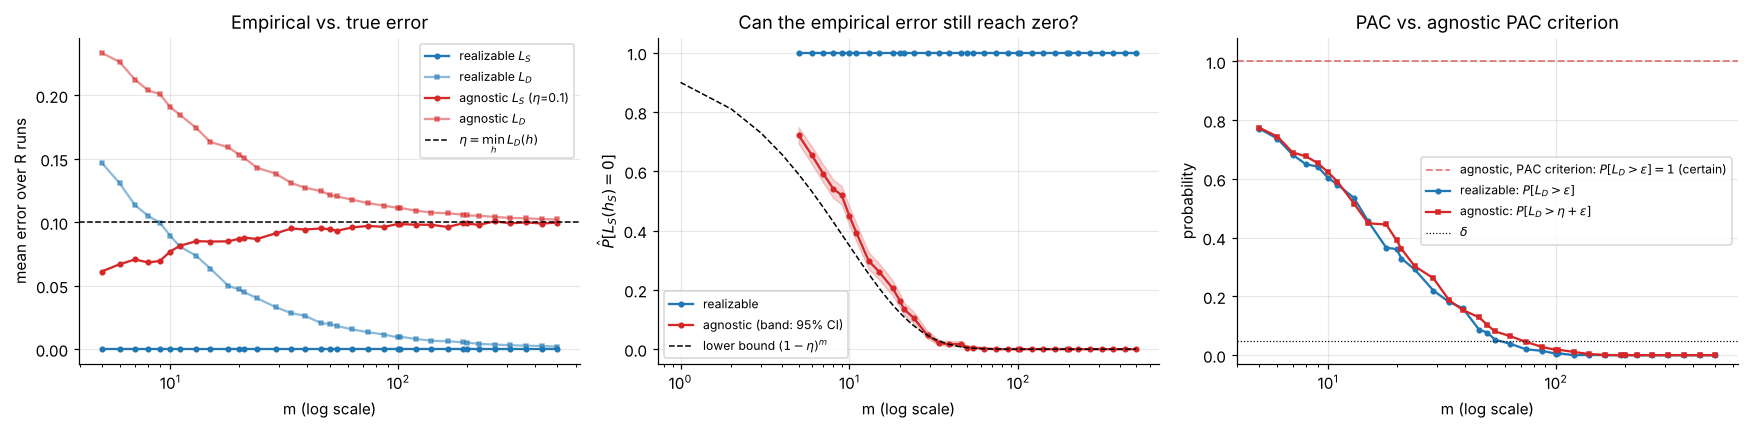

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

ax = axes[0]
ax.plot(M_FINE, ls_r, "o-", ms=3, color="tab:blue", label=r"realizable $L_S$")
ax.plot(M_FINE, ld_r, "s-", ms=3, color="tab:blue", alpha=0.5, label=r"realizable $L_D$")
ax.plot(M_FINE, ls_a, "o-", ms=3, color="tab:red", label=rf"agnostic $L_S$ ($\eta$={ETA})")
ax.plot(M_FINE, ld_a, "s-", ms=3, color="tab:red", alpha=0.5, label=r"agnostic $L_D$")
ax.axhline(ETA, color="k", ls="--", lw=1, label=r"$\eta = \min_h L_D(h)$")
ax.set_xscale("log"); ax.set_xlabel("m (log scale)"); ax.set_ylabel("mean error over R runs")
ax.set_title("Empirical vs. true error"); ax.legend(fontsize=8)

ax = axes[1]
ax.plot(M_FINE, p0_r, "o-", ms=3, color="tab:blue", label="realizable")
ax.fill_between(M_FINE, lo0, hi0, color="tab:red", alpha=0.2)
ax.plot(M_FINE, p0_a, "o-", ms=3, color="tab:red", label="agnostic (band: 95% CI)")
ax.plot(mm, (1 - ETA) ** mm, "k--", lw=1, label=r"lower bound $(1-\eta)^m$")
ax.set_xscale("log"); ax.set_xlabel("m (log scale)"); ax.set_ylabel(r"$\hat P[L_S(h_S)=0]$")
ax.set_title("Can the empirical error still reach zero?"); ax.legend(fontsize=8)

ax = axes[2]
ax.axhline(1.0, color="tab:red", ls="--", lw=1.2, alpha=0.6, label=r"agnostic, PAC criterion: $P[L_D>\varepsilon]=1$ (certain)")
ax.plot(M_FINE, p_fail, "o-", ms=3, color="tab:blue", label=r"realizable: $P[L_D>\varepsilon]$")
ax.plot(M_FINE, p_agn, "s-", ms=3, color="tab:red", label=r"agnostic: $P[L_D>\eta+\varepsilon]$")
ax.axhline(DELTA, color="k", lw=0.8, ls=":", label=r"$\delta$")
ax.set_xscale("log"); ax.set_xlabel("m (log scale)"); ax.set_ylabel("probability"); ax.set_ylim(-0.03, 1.08)
ax.set_title("PAC vs. agnostic PAC criterion"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

**Observation.**
- $L_S(h_S) = 0$ still happens for small samples (72% of the runs at $m = 5$), but it becomes rare: 0.5% at $m = 50$ and never for $m \ge 100$. The estimates stay above the lower bound $(1-\eta)^m$ (at $m = 50$: 0.005 against 0.0052, and the confidence interval $[0.002, 0.012]$ contains the bound).
- The mean training error increases towards $\eta$ from below; the mean true error decreases towards $\eta$ from above (0.1055 at $m = 200$), and never goes below it.
- The PAC criterion fails with probability 1 for every $m$. The agnostic criterion $\Pr[L_{\mathcal D} > \eta + \varepsilon]$ goes to 0: 0.103 at $m = 50$, 0.001 at $m = 200$.

**Explanation.**
- $L_S = 0$ requires that the flipped labels still look separable. This is at least as likely as having no flipped label at all, $(1-\eta)^m$, which decreases exponentially.
- ERM picks the threshold that fits the sample best, including part of the noise, so the training error is optimistic. The true error of every threshold is at least $\eta$: noise cannot be removed by more data.
- What more data does is bring $h_S$ closer to the best hypothesis in $\mathcal H$.

**Link to the course.** Agnostic PAC learnability asks for $L_{\mathcal D}(h_S) \le \min_{h \in \mathcal H} L_{\mathcal D}(h) + \varepsilon$ with probability at least $1-\delta$. Under the PAC criterion this problem would look unlearnable; under the agnostic criterion ERM learns it.

### 5.1 Effect of the noise level $\eta$

The two frameworks only differ by the reference point ($0$ vs. $\min_h L_{\mathcal D}(h)$), but noise also makes learning *slower*: the excess risk $L_{\mathcal D}(h_S) - \eta = (1-2\eta)|\hat t-\theta|$ depends on how well the sample locates $\theta$, and flipped labels near $\theta$ blur that location. As $\eta \to 1/2$, the labels carry no information about $\theta$ at all.

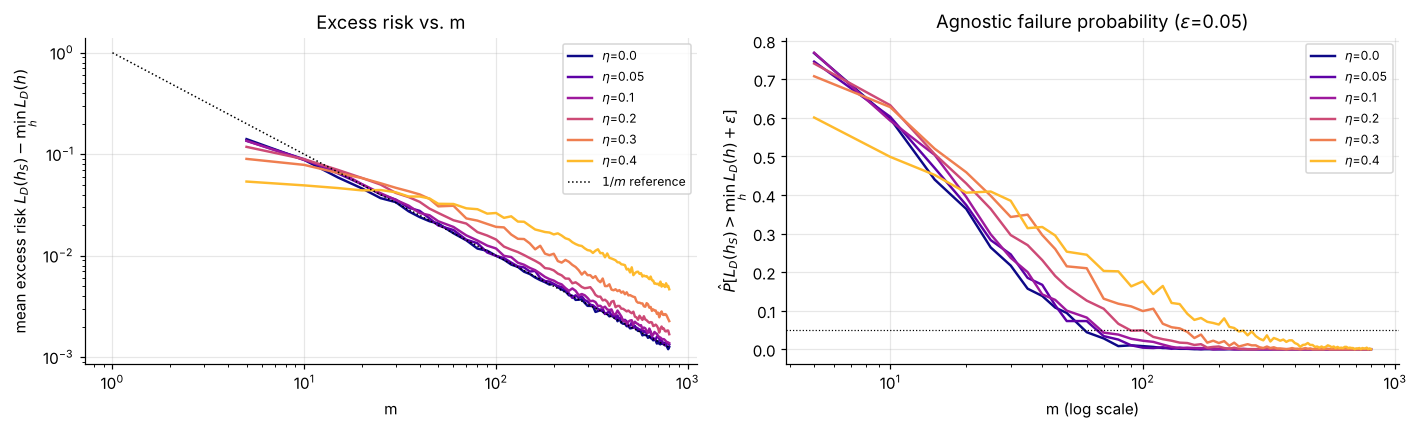

Smallest m (grid step 10, R=1000) with P[excess > eps] <= delta=0.05, and log-log slope of mean excess risk (m >= 50):
  eta = 0.0 : m =    60   slope = -1.00
  eta = 0.05: m =    70   slope = -0.99
  eta = 0.1 : m =    70   slope = -1.00
  eta = 0.2 : m =    90   slope = -1.00
  eta = 0.3 : m =   150   slope = -0.98
  eta = 0.4 : m =   240   slope = -0.78


In [15]:
ETAS_SWEEP = [0.0] + ETAS + [0.4]
M_SWEEP = np.unique(np.concatenate([np.arange(5, 50, 5), np.arange(50, 801, 10)]))  # dense grid for m_needed
res_eta = {}
for i, eta in enumerate(ETAS_SWEEP):
    rng_eta = make_rng(50 + i)
    res_eta[eta] = {m: run_mc(m, rng_eta, eta=eta) for m in M_SWEEP}

colors = dict(zip(ETAS_SWEEP, plt.cm.plasma(np.linspace(0, 0.85, len(ETAS_SWEEP)))))
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
m_needed, slopes = {}, {}
for eta, res in res_eta.items():
    excess = np.array([(res[m][2] - eta).mean() for m in M_SWEEP])
    p = np.array([np.mean(res[m][2] - eta > EPS) for m in M_SWEEP])
    m_needed[eta] = next((int(m) for m, v in zip(M_SWEEP, p) if v <= DELTA), None)
    sel = M_SWEEP >= 50
    slopes[eta] = np.polyfit(np.log(M_SWEEP[sel]), np.log(excess[sel]), 1)[0]
    axes[0].loglog(M_SWEEP, excess, "-", lw=1.6, color=colors[eta], label=rf"$\eta$={eta}")
    axes[1].plot(M_SWEEP, p, "-", lw=1.6, color=colors[eta], label=rf"$\eta$={eta}")
mm8 = np.arange(1, 801)
axes[0].loglog(mm8, 1 / mm8, "k:", lw=1, label=r"$1/m$ reference")
axes[0].set_xlabel("m"); axes[0].set_ylabel(r"mean excess risk $L_D(h_S) - \min_h L_D(h)$")
axes[0].set_title("Excess risk vs. m"); axes[0].legend(fontsize=8)
axes[1].axhline(DELTA, color="k", lw=0.8, ls=":")
axes[1].set_xscale("log"); axes[1].set_xlabel("m (log scale)")
axes[1].set_ylabel(r"$\hat P[L_D(h_S) > \min_h L_D(h) + \varepsilon]$")
axes[1].set_title(rf"Agnostic failure probability ($\varepsilon$={EPS})"); axes[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

print(f"Smallest m (grid step 10, R={R}) with P[excess > eps] <= delta={DELTA}, and log-log slope of mean excess risk (m >= 50):")
for eta in ETAS_SWEEP:
    mn = m_needed[eta]
    print(f"  eta = {eta:<4}: m = {mn if mn is not None else '> ' + str(M_SWEEP.max()):>5}   slope = {slopes[eta]:.2f}")

**Observation.** For every $\eta < 1/2$ the excess risk goes to 0. The required sample size grows with $\eta$: 60 ($\eta = 0$), 70 ($\eta = 0.1$), 90 ($\eta = 0.2$), 150 ($\eta = 0.3$), 240 ($\eta = 0.4$), i.e. 4 times more between $\eta = 0$ and $\eta = 0.4$. The mean excess risk decreases like $1/m$ (slopes close to $-1$), except for $\eta = 0.4$ (slope $-0.78$).

**Explanation.** Near $\theta$, labels are wrong with probability $\eta$, so the empirical risk is flatter around $\theta$ and $\hat t$ is less precise: more data is needed. At low noise the factor $(1-2\eta)$ partly compensates, because the condition "excess $> \varepsilon$" becomes $|\hat t - \theta| > \varepsilon/(1-2\eta)$, which is looser. For $\eta = 0.4$ the curve has probably not yet reached its asymptotic regime with $m \le 800$.

**Link to the course.** The general agnostic bounds of the course (via uniform convergence) give an excess risk of order $1/\sqrt m$, i.e. $m \propto 1/\varepsilon^2$. That is a worst case over all distributions. Here the noise is the same everywhere and stays away from $1/2$, which is an easy case, and we observe the faster $1/m$ rate. We did not build a hard distribution, so this experiment does not show the $1/\sqrt m$ rate; it only shows that the general bound is not tight for this problem.

## 6. Agnostic PAC with a target outside the class

In Section 5 the best classifier was still a threshold; only the noise prevented zero error. Now the labels are **noise-free**, but they come from an interval: $y = \mathbb 1[a < x \le b]$ with $(a, b) = (0.3, 0.8)$. No threshold can represent this rule. For $h_t(x) = \mathbb 1[x > t]$:
$$L_{\mathcal D}(h_t) = \begin{cases} |t-a| + (1-b) & t \le b \\ (b-a) + (1-t) & t > b \end{cases}$$
The best threshold is $t^* = a = 0.3$, with $\min_h L_{\mathcal D}(h) = 1-b = 0.2$: it gets the left boundary right but wrongly predicts 1 on $(0.8, 1]$. The Bayes error is 0, because the interval rule itself makes no mistake. So the true error of ERM splits into two parts:
$$L_{\mathcal D}(h_S) = \underbrace{\min_{h\in\mathcal H} L_{\mathcal D}(h) - L_{\text{Bayes}}}_{\text{approximation error} \;=\; 0.2} + \underbrace{L_{\mathcal D}(h_S) - \min_{h\in\mathcal H} L_{\mathcal D}(h)}_{\text{estimation error}}.$$

t = 0.0: L_D exact = 0.5000   test set = 0.5029
t = 0.2: L_D exact = 0.3000   test set = 0.3013
t = 0.3: L_D exact = 0.2000   test set = 0.2009
t = 0.5: L_D exact = 0.4000   test set = 0.3980
t = 0.8: L_D exact = 0.7000   test set = 0.6979
t = 0.9: L_D exact = 0.6000   test set = 0.5963

Best threshold in H: t* = 0.300,  min_h L_D(h) = 0.200.  Bayes error = 0.0.


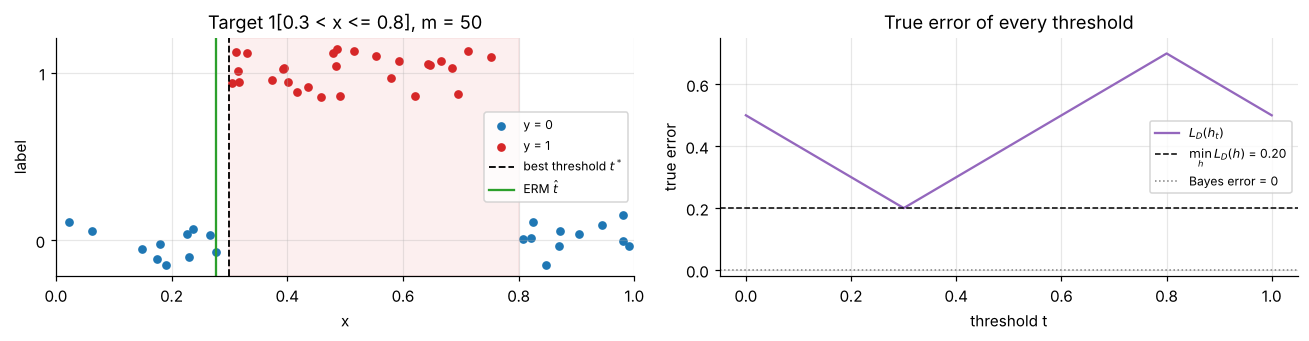

This sample: t_hat = 0.277, L_S = 0.220, L_D = 0.223


In [16]:
A, B = 0.3, 0.8      # the target is the interval (A, B]

def generate_interval(m, rng, n_rep=None, a=A, b=B):
    # Labels y = 1[a < x <= b], no noise.
    shape = (m,) if n_rep is None else (n_rep, m)
    X = rng.random(shape)
    return X, ((X > a) & (X <= b)).astype(np.int8)

def true_risk_interval(t, a=A, b=B):
    # Exact L_D(h_t) for h_t(x) = 1[x > t] when x ~ U[0,1] and y = 1[a < x <= b].
    t = np.asarray(t, dtype=float)
    return np.where(t <= b, np.abs(t - a) + (1 - b), (b - a) + (1 - t))

t_grid = np.linspace(0, 1, 100_001)
L_STAR = true_risk_interval(t_grid).min()            # best error inside the class H
T_STAR = t_grid[np.argmin(true_risk_interval(t_grid))]
BAYES = 0.0                                          # f(x) = 1[a < x <= b] itself has zero error

# Check the formula on an independent test set
X_te_i, y_te_i = generate_interval(N_TEST, make_rng(60))
for t in [0.0, 0.2, A, 0.5, B, 0.9]:
    print(f"t = {t:.1f}: L_D exact = {float(true_risk_interval(t)):.4f}   test set = {empirical_risk(t, X_te_i, y_te_i):.4f}")
print(f"\nBest threshold in H: t* = {T_STAR:.3f},  min_h L_D(h) = {L_STAR:.3f}.  Bayes error = {BAYES}.")

X, y = generate_interval(50, make_rng(61))
t_hat_i, ls_i = erm_threshold(X, y)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.2))
plot_dataset(axes[0], X, y, rf"Target 1[{A} < x <= {B}], m = 50", theta=T_STAR, t_hat=t_hat_i,
             theta_label=r"best threshold $t^*$")
axes[0].axvspan(A, B, color="tab:red", alpha=0.07)
axes[1].plot(t_grid, true_risk_interval(t_grid), color="tab:purple", label=r"$L_D(h_t)$")
axes[1].axhline(L_STAR, color="k", ls="--", lw=1, label=rf"$\min_h L_D(h)$ = {L_STAR:.2f}")
axes[1].axhline(BAYES, color="grey", ls=":", lw=1, label="Bayes error = 0")
axes[1].set_xlabel("threshold t"); axes[1].set_ylabel("true error"); axes[1].set_ylim(-0.02, 0.75)
axes[1].set_title("True error of every threshold"); axes[1].legend(fontsize=8)
plt.tight_layout(); plt.show()
print(f"This sample: t_hat = {t_hat_i:.3f}, L_S = {ls_i:.3f}, L_D = {float(true_risk_interval(t_hat_i)):.3f}")

**Observation.** The exact formula matches the test set within 0.004. On this sample, ERM puts $\hat t$ near 0.3 and gets $L_S = 0.22$: the training error is positive although there is no noise at all.

**Explanation.** Points in $(0.8, 1]$ have $y = 0$, but any threshold that predicts 1 on $(0.3, 0.8]$ also predicts 1 there. The class cannot express "back to 0 after 0.8", so the error comes from the model, not from the data.

**Link to the course.** This is the real meaning of "agnostic": we make no assumption that the target belongs to $\mathcal H$.

   m | mean L_S | mean L_D | approx. error | estim. error | P[L_S=0] | P[L_D > L*+eps]
   5 |   0.1592 |   0.3753 |        0.2000 |       0.1753 |    0.354 |           0.799
  10 |   0.1855 |   0.3085 |        0.2000 |       0.1085 |    0.107 |           0.641
  20 |   0.1976 |   0.2543 |        0.2000 |       0.0543 |    0.009 |           0.358
  50 |   0.1986 |   0.2218 |        0.2000 |       0.0218 |    0.000 |           0.106
 100 |   0.1999 |   0.2105 |        0.2000 |       0.0105 |    0.000 |           0.013
 200 |   0.2011 |   0.2050 |        0.2000 |       0.0050 |    0.000 |           0.000


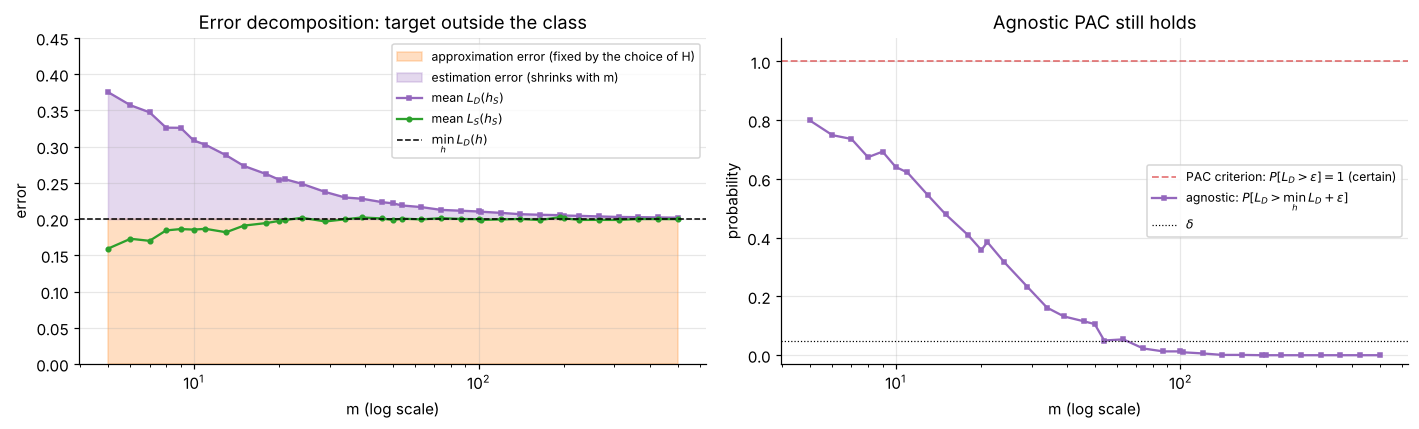

Smallest m on the grid with P[L_D > L* + eps] <= delta: 54


In [17]:
rng_int = make_rng(62)
itv = {}
for m in M_FINE:
    X, y = generate_interval(m, rng_int, n_rep=R)
    t_hat, ls = erm_threshold(X, y)
    itv[m] = (t_hat, ls, true_risk_interval(t_hat))

ls_i = np.array([itv[m][1].mean() for m in M_FINE])
ld_i = np.array([itv[m][2].mean() for m in M_FINE])
est_i = ld_i - L_STAR                                           # estimation error
p0_i = np.array([np.mean(itv[m][1] == 0) for m in M_FINE])
p_agn_i = np.array([np.mean(itv[m][2] > L_STAR + EPS) for m in M_FINE])

print(f"{'m':>4} | {'mean L_S':>8} | {'mean L_D':>8} | {'approx. error':>13} | {'estim. error':>12} | {'P[L_S=0]':>8} | {'P[L_D > L*+eps]':>15}")
for m in M_GRID:
    i = list(M_FINE).index(m)
    print(f"{m:>4} | {ls_i[i]:8.4f} | {ld_i[i]:8.4f} | {L_STAR - BAYES:13.4f} | {est_i[i]:12.4f} | {p0_i[i]:8.3f} | {p_agn_i[i]:15.3f}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
ax = axes[0]
ax.fill_between(M_FINE, BAYES, L_STAR, color="tab:orange", alpha=0.25, label="approximation error (fixed by the choice of H)")
ax.fill_between(M_FINE, L_STAR, ld_i, color="tab:purple", alpha=0.25, label="estimation error (shrinks with m)")
ax.plot(M_FINE, ld_i, "s-", ms=3, color="tab:purple", label=r"mean $L_D(h_S)$")
ax.plot(M_FINE, ls_i, "o-", ms=3, color="tab:green", label=r"mean $L_S(h_S)$")
ax.axhline(L_STAR, color="k", ls="--", lw=1, label=r"$\min_h L_D(h)$")
ax.set_xscale("log"); ax.set_xlabel("m (log scale)"); ax.set_ylabel("error"); ax.set_ylim(0, 0.45)
ax.set_title("Error decomposition: target outside the class"); ax.legend(fontsize=8)
ax = axes[1]
ax.axhline(1.0, color="tab:red", ls="--", lw=1.2, alpha=0.6, label=r"PAC criterion: $P[L_D>\varepsilon]=1$ (certain)")
ax.plot(M_FINE, p_agn_i, "s-", ms=3, color="tab:purple", label=r"agnostic: $P[L_D > \min_h L_D + \varepsilon]$")
ax.axhline(DELTA, color="k", lw=0.8, ls=":", label=r"$\delta$")
ax.set_xscale("log"); ax.set_xlabel("m (log scale)"); ax.set_ylabel("probability"); ax.set_ylim(-0.03, 1.08)
ax.set_title("Agnostic PAC still holds"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()
m_need_i = next((int(m) for m, p in zip(M_FINE, p_agn_i) if p <= DELTA), None)
print(f"Smallest m on the grid with P[L_D > L* + eps] <= delta: {m_need_i}")

**Observation.** The mean true error decreases towards 0.2, never towards 0. The estimation error goes from 0.175 ($m = 5$) to 0.005 ($m = 200$), while the approximation error stays at 0.2. For large $m$ the mean training error is about 0.2 (in theory $\mathbb E[L_S(h_S)] \le 0.2$; the value 0.2011 at $m = 200$ is within Monte Carlo noise, whose standard error is about 0.001). The PAC criterion fails with certainty, while $\Pr[L_{\mathcal D} > \min_h L_{\mathcal D} + \varepsilon]$ goes to 0 and is below $\delta$ from $m \approx 54$.

**Explanation.** More data locates the best threshold more precisely, so the estimation error goes to 0. The approximation error depends only on $\mathcal H$ and on the distribution: it is the same 0.2 for every $m$. To reduce it, we would need a richer class (for example intervals), which in turn needs more data to estimate.

**Link to the course.** This is the decomposition of the error into approximation error and estimation error (the bias–complexity trade-off). Agnostic PAC compares ERM with the best hypothesis in $\mathcal H$, not with the Bayes predictor: ERM on thresholds is an agnostic PAC learner here even though it never learns the true rule.

## 7. Conclusion: PAC vs. Agnostic PAC

| | Realizable (PAC) | Agnostic: label noise | Agnostic: target outside $\mathcal H$ |
|---|---|---|---|
| Data | $y = \mathbb 1[x > \theta]$ | labels flipped with probability $\eta = 0.1$ | $y = \mathbb 1[0.3 < x \le 0.8]$, no noise |
| Best in $\mathcal H$ vs. Bayes | both 0 | both $\eta$ ($h_\theta$ is Bayes optimal) | $\min_h L_{\mathcal D} = 0.2 >$ Bayes $= 0$ |
| Training error of ERM | always 0 | 0 only for tiny $m$; tends to $\eta$ from below | 0 only for tiny $m$; tends to 0.2 |
| True error of ERM | $\to 0$, mean $\approx 1/(m+1)$ | $\to \eta$, never below | $\to 0.2$, never below |
| PAC criterion $L_{\mathcal D} \le \varepsilon$ | holds, $m^\star = 59$ | fails with certainty ($\eta > \varepsilon$) | fails with certainty ($0.2 > \varepsilon$) |
| Agnostic criterion | same as PAC | holds, $m \approx 70$ | holds, $m \approx 54$ |

1. **ERM on thresholds is a PAC learner.** The failure probability decreases exponentially and matches $(1-\varepsilon)^m$; the sample size scales like $\log(1/\delta)/\varepsilon$ and does not depend on $\theta$. The class is infinite, so a finite class is not necessary for learnability.
2. **The finite-class bound of the course is valid but loose.** It grows with $\log|\mathcal H|$ (153 to 475 examples) while the real need stays around 59. Counting hypotheses is not the right measure of complexity for this class.
3. **Realizability can fail in two ways.** With noise, the error floor is the Bayes error. With a target outside the class, the floor is the approximation error of $\mathcal H$. In both cases the training error stops being 0, the true error has a floor, and the PAC criterion becomes impossible once $\varepsilon$ is below that floor.
4. **The agnostic framework restores a meaningful guarantee** by comparing with the best hypothesis in $\mathcal H$. More data reduces the estimation error only; the approximation error depends on the choice of $\mathcal H$.
5. **The training error is not a reliable proxy for the true error**: it is 0 whatever the quality in the realizable case, and optimistic in the agnostic case. This motivates the uniform-convergence analysis of the next session.